# [GPU 실습] GPU는 얼마나 빠를까? · 학습 중 GPU 지켜보기
강의장 노트북(VS Code)에서 실행해요. Ollama가 켜져 있어야 해요 — 터미널에서 `ollama list`로 확인

In [1]:
# ▶ 환경 준비 — Colab · VS Code 공통, 맨 처음 한 번 실행
import os, sys, platform, subprocess
IN_COLAB = 'google.colab' in sys.modules

def gpu_info():
    try:
        r = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total', '--format=csv,noheader'],
                           capture_output=True, text=True, timeout=10)
        return r.stdout.strip() or None
    except Exception:
        return None

GPU = gpu_info()
print('실행 위치:', 'Colab' if IN_COLAB else f'내 컴퓨터 ({platform.system()})')
print('GPU:', GPU or '없음 → CPU로 실행 (이 노트북은 CPU로도 충분해요)')

# (선택) pandas를 GPU로 — Colab GPU 런타임 또는 Linux/WSL에 cuDF가 있을 때만
USE_GPU_PANDAS = False          # True로 바꾸고 이 칸을 다시 실행
if USE_GPU_PANDAS and GPU:
    try:
        get_ipython().run_line_magic('load_ext', 'cudf.pandas')
        print('pandas → GPU(cuDF) 사용')
    except Exception as e:
        print('cuDF를 쓸 수 없어 일반 pandas로 실행:', type(e).__name__)

# 한글 글꼴: Colab은 나눔고딕 설치, 윈도우는 맑은 고딕, 맥은 애플고딕
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
if IN_COLAB:
    nanum = '/usr/share/fonts/truetype/nanum/NanumGothic.ttf'
    if not os.path.exists(nanum):
        subprocess.run('apt-get -qq install -y fonts-nanum > /dev/null', shell=True)
    fm.fontManager.addfont(nanum)
    plt.rcParams['font.family'] = 'NanumGothic'
elif platform.system() == 'Windows':
    plt.rcParams['font.family'] = 'Malgun Gothic'
elif platform.system() == 'Darwin':
    plt.rcParams['font.family'] = 'AppleGothic'
else:                                   # 리눅스·WSL: 설치된 한글 글꼴 찾기
    ko = [f.name for f in fm.fontManager.ttflist if 'Nanum' in f.name or 'CJK KR' in f.name]
    if ko: plt.rcParams['font.family'] = ko[0]
plt.rcParams['axes.unicode_minus'] = False
print('한글 글꼴:', plt.rcParams['font.family'])

실행 위치: 내 컴퓨터 (Windows)
GPU: NVIDIA GeForce RTX 5070 Laptop GPU, 8151 MiB
한글 글꼴: ['Malgun Gothic']


## 1. 같은 질문, GPU와 CPU로 한 번씩 — 1초에 몇 토큰?

In [2]:
import requests, time, subprocess
import pandas as pd

MODEL = 'qwen2.5:3b'          # ollama list 에 있는 모델 이름 (없으면: ollama pull qwen2.5:3b)
Q = '미세먼지 농도가 높은 날 외출할 때 주의할 점을 세 문장으로 써 줘.'

def speed(use_gpu=True):
    opts = {'temperature': 0, 'num_predict': 200}
    if not use_gpu:
        opts['num_gpu'] = 0               # GPU에 올리는 층 0개 = CPU만 사용
    r = requests.post('http://localhost:11434/api/generate',
                      json={'model': MODEL, 'prompt': Q, 'stream': False, 'options': opts},
                      timeout=900).json()
    return r['eval_count'] / (r['eval_duration'] / 1e9)     # 초당 토큰 수

speed()                                    # 첫 실행은 모델을 올리는 시간이 섞여서 버림
gpu_tps = speed(True)
cpu_tps = speed(False)
print(f'GPU {gpu_tps:.0f} 토큰/초 · CPU {cpu_tps:.0f} 토큰/초 → {gpu_tps / cpu_tps:.1f}배')

GPU 101 토큰/초 · CPU 23 토큰/초 → 4.3배


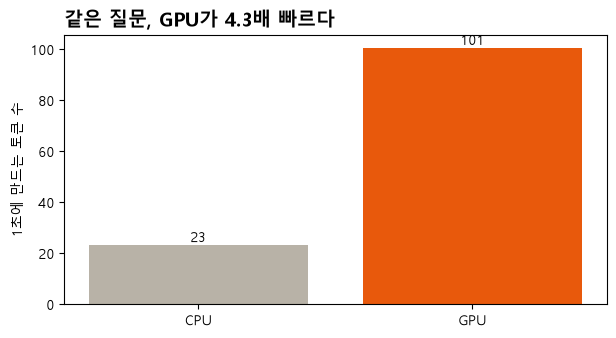

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.bar(['CPU', 'GPU'], [cpu_tps, gpu_tps], color=['#B8B2A7', '#E8590C'])
ax.bar_label(bars, fmt='%.0f'); ax.set_ylabel('1초에 만드는 토큰 수')
ax.set_title(f'같은 질문, GPU가 {gpu_tps / cpu_tps:.1f}배 빠르다', loc='left', fontsize=14, fontweight='bold')
plt.show()

## 2. 학습하는 동안 GPU 지켜보기
1. Unsloth Studio에서 학습을 **시작**한 뒤
2. 아래 칸을 실행 → 2초마다 GPU 메모리·사용률을 기록해요

In [4]:
def watch(seconds=120, every=2):
    rows, t0 = [], time.time()
    while time.time() - t0 < seconds:
        out = subprocess.run(['nvidia-smi', '--query-gpu=memory.used,memory.total,utilization.gpu',
                              '--format=csv,noheader,nounits'], capture_output=True, text=True).stdout
        used, total, util = [float(x) for x in out.strip().split(',')]
        rows.append({'초': round(time.time() - t0), '메모리(GB)': used / 1024, '전체(GB)': total / 1024, '사용률(%)': util})
        time.sleep(every)
    return pd.DataFrame(rows)

log = watch(120)
log.tail()

,초,메모리(GB),전체(GB),사용률(%)
54,111,2.865234,7.959961,0.0
55,113,2.865234,7.959961,0.0
56,115,2.865234,7.959961,0.0
57,117,2.865234,7.959961,0.0
58,119,2.865234,7.959961,0.0


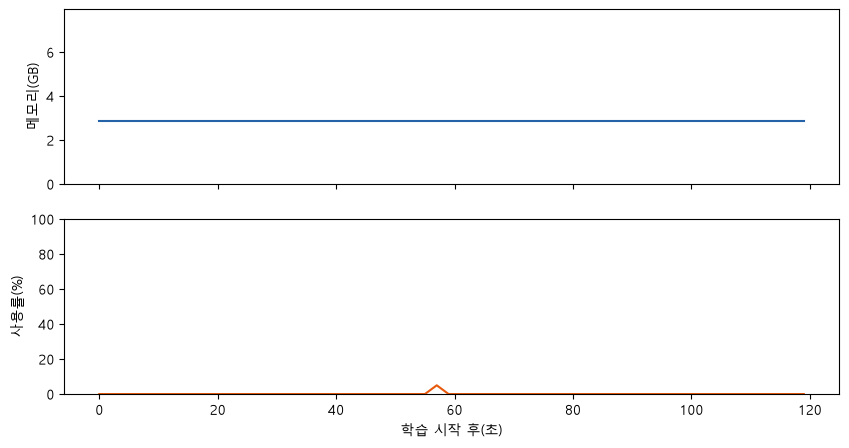

최대 메모리 2.9GB / 8GB


In [5]:
# 축이 다른 두 값 → 위아래 두 칸 (같은 시간축)
fig, (a, b) = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
a.plot(log['초'], log['메모리(GB)'], color='#2563A8'); a.set_ylim(0, log['전체(GB)'].max())
a.set_ylabel('메모리(GB)')
b.plot(log['초'], log['사용률(%)'], color='#E8590C'); b.set_ylim(0, 100)
b.set_ylabel('사용률(%)'); b.set_xlabel('학습 시작 후(초)')
plt.show()
print(f"최대 메모리 {log['메모리(GB)'].max():.1f}GB / {log['전체(GB)'].max():.0f}GB")

### 읽는 법
- 메모리가 거의 꽉 찼다면 → 배치 크기나 컨텍스트 길이를 줄이면 '메모리 부족' 오류를 피할 수 있어요.
- 사용률이 90% 안팎이면 GPU가 쉬지 않고 일하는 중이에요.